<a href="https://colab.research.google.com/github/JuaaanDavid/Practica-3-El-Perceptron-/blob/main/Practica_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universidad Politecnica Salesiana
# Carrera de Computación
Nombre: Juan Nuñez

Fecha: 13/11/2026


Practica 03: EL PERCEPTRÓN

# Fase 1: Exploración del Dataset

#1.1 carga del dataset

In [1]:
X = [[1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2], [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9], [12, 6], [14, 7], [16, 4]]
y = [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1,  1,  1,  1,  1,  1,  1,  1,  1]

instancias = len(X)
print("Número de instancias: ", instancias)

variables_entrada = len(X[0])
print("Número de variables de entrada: ", variables_entrada)


puntos_clase= []
menos_uno= 0
mas_uno= 0

for i in y:
  if i not in puntos_clase:
    puntos_clase.append(i)
  if i == -1:
    menos_uno += 1
  elif i == 1:
    mas_uno += 1


print("Número de clases: ", len(puntos_clase), puntos_clase)
print("Puntos por clase -1: ", menos_uno)
print("Puntos por clase +1: ", mas_uno)



Número de instancias:  23
Número de variables de entrada:  2
Número de clases:  2 [-1, 1]
Puntos por clase -1:  14
Puntos por clase +1:  9


**Actividad 1.a — Inspección inicial**


Identifica los siguientes datos:


- Número total de instancias

Hay un total de 23 instancias

- Variables de entrada

Hay 2 variables de entrada

- Número de clases

Hay 2 número de clase (-1, +1)

- Cantidad de puntos por clase

Hay 23 puntos en total, 14 para la clase -1 y 9 para la clase +1

 - Pregunta guía: ¿Qué representa cada fila de X? ¿Qué representa cada valor del vector y? ¿Por qué este problema se considera de clasificación binaria?

Cada fila de X representa una instancia del dataset, las cuales estan definidas como x1 y x2

Cada valor del vector y representa la clase a la que pertenece cada instancia de X

Este problema se puede considerar de clasificacion binaria por que el objetivo es asignar cada punto en dos categorias (-1, +1)


**Actividad 1.b — Separación visual de las clases**

Crea una función que permita grafica los puntos en un plano cartesiano, utiliza un marcador diferente para
la clase -1 y para la clase 1. Puedes utilizar matplotlib para esta actividad

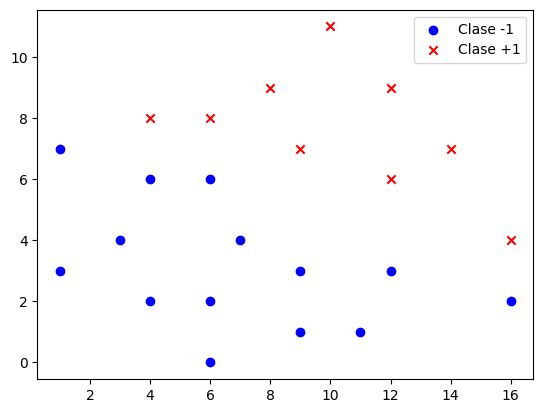

In [2]:
import matplotlib.pyplot as plt

def grafica_puntos(X, y):
  x1_negativo, x2_negativo= [],[]
  x1_positivo, x2_positivo= [],[]

  for i in range(len(X)):
    if y[i] == -1:
      x1_negativo.append(X[i][0])
      x2_negativo.append(X[i][1])
    else:
      x1_positivo.append(X[i][0])
      x2_positivo.append(X[i][1])

  plt.scatter(x1_negativo, x2_negativo, color='blue', marker='o', label='Clase -1')
  plt.scatter(x1_positivo, x2_positivo, color='red', marker='x', label='Clase +1')
  plt.legend()
  plt.show()

grafica_puntos(X, y)






- Pregunta guía: Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta

Se puede separar ya que en la grafica se puede ver que ningun punto se esta mezclando con el otro

# Fase 2. Fundamento del Perceptrón

**Actividad 2.a — Vector de pesos**

Crea una función llamada initialize_weights() que retorne tres pesos aleatorios pequeños. Los
pesos deben generarse en un rango pequeño, por ejemplo entre -0.5 y 0.5.

In [3]:
import random
def  initialize_weights():
  w0 = random.uniform(-0.5, 0.5)
  w1 = random.uniform(-0.5, 0.5)
  w2 = random.uniform(-0.5, 0.5)
  return [w0, w1, w2]


- Pregunta guía: ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias en el modelo?

Tiene 3 valores por que aparte de las 2 variables de entrada (w1 para x1 y w2 para x2) necesita un w0 que corresponde al bias

La funcion del bias es que permite desplazar la frontera de decision, permitiendo separar muchos conjuntos de datos, sin el bias, la recta solo podria rotar alrededor del origen


**Actividad 2.b — Función de activación**

Crea una función llamada activation(z) que reciba el valor de la suma ponderada y retorne el
resultado de la función escalón bipolar:


In [4]:
def activation(z):
  if z >= 0:
    return 1
  else:
    return -1

- Pregunta guía: ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?

Se usan las etiquetas -1 y 1 por que es una representacion simetrica alrededor del 0

La ventaja es que facilita y hace simetrica la regla de actualizacion de pesos, cuando hay un error, el termino $(y - \hat{y})$ siempre vale +2 o -2, empujando los pesos en cualquiera de las dos direcciones para corregir la frontera

**Actividad 2.c — Cálculo de salida**

Crea una función llamada perceptron_compute(x, w). La función debe recibir una sola instancia x = [x1, x2] y el vector de pesos w = [w0, w1, w2]. Esta función debe calcular la suma ponderada z y
retornar la salida producida por la función de activación.

In [5]:
def perceptron_compute (x, w):
  z= w[0] + w[1] * x[0] + w[2] * x[1]
  return activation(z)

#Prueba manual
w_prueba= initialize_weights()
print("Pesos de prueba: ", w_prueba)

indices_prueba= [0, 14, 22]

for i in indices_prueba:
  prediccion= perceptron_compute (X[i], w_prueba)
  print("Instancia: ", X[i], "Prediccion: ", prediccion)



Pesos de prueba:  [0.3706588633079577, 0.09678759313541896, -0.32465941316354585]
Instancia:  [1, 7] Prediccion:  -1
Instancia:  [4, 8] Prediccion:  -1
Instancia:  [16, 4] Prediccion:  1


- Pregunta guía: ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Por qué no basta con calcular solo z?

La diferencia es que la suma ponderada z es un numero continuo que indica que tan lejos y de que lado de la recta esta el punto, mientras que la salida final del perceptron es un valor discreto y binario que representa la clase asignada

No basta con calcular solo z por que el objetivo del perceptron es tomar una decision de clasificacion binaria, la funcion de activacion es la que convierte ese valor continuo de z en una etiqueta con la cual se puede comparar con la clase real y para saber si el modelo acerto o cometio un error


# Fase 3. Visualización de la Frontera de Decisión

**3.1 Actividades de visualización**

**Actividad 3.a — Función de graficación**


- Crea una función llamada perceptron_plot(X, y, w, title). La función debe:

• Graficar los puntos de la clase -1.

• Graficar los puntos de la clase 1.

• Graficar la frontera de decisión correspondiente al vector de pesos w.

• Colocar título, etiquetas de ejes, leyenda y cuadrícula.

- Considera el siguiente caso especial:

• Si w2 ≠ 0, puedes despejar x2

• Si w2 = 0, la recta no puede despejarse de esa forma y debes evitar la división para cero.

In [6]:
def perceptron_plot(X, y, w, title):
  x1_negativo, x2_negativo = [], []
  x1_positivo, x2_positivo = [], []
  for i in range(len(X)):
    if y[i] == -1:
      x1_negativo.append(X[i][0])
      x2_negativo.append(X[i][1])
    else:
      x1_positivo.append(X[i][0])
      x2_positivo.append(X[i][1])

  # Puntos negativos y positivos
  plt.scatter(x1_negativo, x2_negativo, color='blue', marker='o', label='Clase -1')
  plt.scatter(x1_positivo, x2_positivo, color='red', marker='x', label='Clase +1')

  # Frontera de decisión
  w0, w1, w2 = w[0], w[1], w[2]

  if w2 != 0:
    x1_valor = [0, 17]
    x2_valor = [-(w0 + w1 * x1) / w2 for x1 in x1_valor]
    plt.plot(x1_valor, x2_valor, color='green', label='Frontera de Decisión')
  elif w1 != 0:
    x1_constante = -w0 / w1
    plt.axvline(x=x1_constante, color='green', label='Frontera de Decisión')
  else:
    print("w1 y w2 son 0")
  plt.title(title)
  plt.xlabel('x1')
  plt.ylabel('x2')
  plt.legend()
  plt.grid(True)
  plt.show()


- Pregunta guía: ¿Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si los pesos iniciales son aleatorios?

La recta generada representa la frontera de decision la cual se encarga de dividir el plano, lo que cae de un lado se clasifica como +1 y del otro lado -1


Si los pesos iniciales son aleatorios, la recta aparece con una posicion e inclinacion completamente distorsionado en el plano, sin relacionarse con la distribucion real de los datos

**Actividad 3.b — Gráfica con pesos iniciales**

Inicializa pesos aleatorios pequeños y grafica la frontera inicial.


Pesos iniciales: [0.05864046613853935, -0.18985413318840538, -0.2627096872504233]




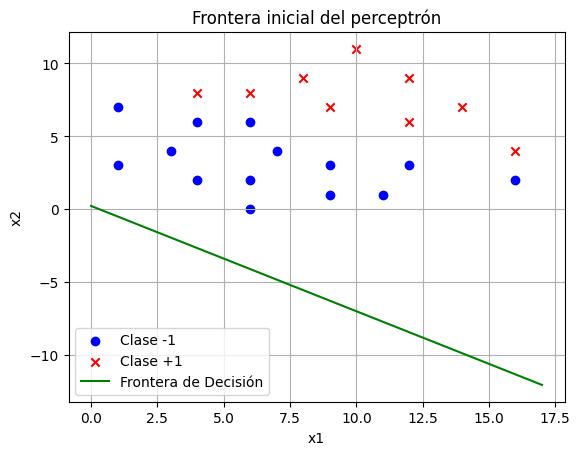

In [7]:
w_inicial = initialize_weights()
print("Pesos iniciales:", w_inicial)
print("\n")
perceptron_plot(X, y, w_inicial, "Frontera inicial del perceptrón")

- Pregunta guía: ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?

La frontera de decision no clasifica correctamente los puntos, y es mucha casualidad de que pase cerca de estos, dejando muchos puntos mal clasificados

No debemos esperar a que una frontera de pesos aleatorios sea correcta ya que el modelo aun no ha aprendido ningun proceso de aprendizaje ni ha ajustado sus pesos y tampoco ha visto los datos


# Fase 4. Entrenamiento del Perceptrón

**4.1 Actividades de entrenamiento**


**Actividad 4.a — Implementación de la función de aprendizaje**


- Crea una función llamada perceptron_learning(X, y, w, lr, max_epochs). La función debe recibir:

• Matriz de datos X

• Vector de etiquetas y

• Pesos iniciales w

• tasa de aprendizaje lr

• Número máximo de épocas max_epochs.

- La función debe retornar:

• Pesos finales

• Número de épocas realizadas

• Número total de actualizaciones

• Lista con la evolución de pesos W_values;

• Lista con la evolución del error E_values.

- La función debe entrenar hasta que:

• No exista ningún error de clasificación en una época o

• Se alcance el número máximo de épocas.

In [8]:
def perceptron_learning(X, y, w, lr, max_epochs):
  w = w.copy()
  total_actualizaciones= 0
  epoch_actualizacion= 0
  total_instancias= len(X)

  for epoch in range(max_epochs):
    errores= 0
    epoch_actualizacion += 1
    for i in range(total_instancias):
      x_i = X[i]
      y_real= y[i]
      y_pred= perceptron_compute(x_i, w)

      if y_pred != y_real:
        errores += 1
        total_actualizaciones += 1
        error = y_real - y_pred
        # Bias
        w[0] = w[0] + lr * error
        # w1
        w[1] = w[1] + lr * error * x_i[0]
        # w2
        w[2] = w[2] + lr * error * x_i[1]
    if errores == 0:
      break

  return w, epoch_actualizacion, total_actualizaciones


- Pregunta guía: ¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?

Se debe incluir un numero maximo de epocas para evitar que el algoritmo no se quede atrapado en un bucle en caso de que no logre encontrar una frontera que separe los datos sin errores


Si el dataset no fuera linealmente separable, el perceptron nunca podria llegar a cero errores, los pesos se seguirian actualizando indefinidamente y el programa se colgaria si no existiera el limite de max_epochs


**Actividad 4.b — Registro del error**

Durante cada época, calcula la tasa de error:

In [9]:
def perceptron_learning(X, y, w, lr, max_epochs):
  w = w.copy()
  E_values= []
  total_actualizaciones= 0
  epoch_actualizacion= 0
  total_instancias= len(X)

  for epoch in range(max_epochs):
    errores= 0
    epoch_actualizacion += 1
    for i in range(total_instancias):
      x_i = X[i]
      y_real= y[i]
      y_pred= perceptron_compute(x_i, w)

      if y_pred != y_real:
        errores += 1
        total_actualizaciones += 1
        error = y_real - y_pred
        # Bias
        w[0] = w[0] + lr * error
        # w1
        w[1] = w[1] + lr * error * x_i[0]
        # w2
        w[2] = w[2] + lr * error * x_i[1]

    #Registro de errores
    tasa_error= errores / total_instancias
    E_values.append(tasa_error)

    if errores == 0:
      break

  return w, epoch_actualizacion, total_actualizaciones, E_values


- Pregunta guía: ¿Qué significa que la tasa de error llegue a cero?


Significa que el perceptron logro clasificar correctamente las instancias del conjunto de entrenamiento en esa epoca

**Actividad 4.c — Registro de pesos**

Después de cada época, guarda una copia del vector de pesos en W_values. Importante: no guardes la misma referencia del objeto w; guarda una copia de sus valores.

In [10]:
def perceptron_learning(X, y, w, lr, max_epochs):
  w = w.copy()
  E_values= []
  W_values= []
  total_actualizaciones= 0
  epoch_actualizacion= 0
  total_instancias= len(X)

  for epoch in range(max_epochs):
    errores= 0
    epoch_actualizacion += 1
    for i in range(total_instancias):
      x_i = X[i]
      y_real= y[i]
      y_pred= perceptron_compute(x_i, w)

      if y_pred != y_real:
        errores += 1
        total_actualizaciones += 1
        error = y_real - y_pred
        # Bias
        w[0] = w[0] + lr * error
        # w1
        w[1] = w[1] + lr * error * x_i[0]
        # w2
        w[2] = w[2] + lr * error * x_i[1]

    #Registro de errores
    tasa_error= errores / total_instancias
    E_values.append(tasa_error)

    #Copia de pesos
    W_values.append(w.copy())

    if errores == 0:
      break

  return w, epoch_actualizacion, total_actualizaciones,W_values, E_values


- Pregunta guía: ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?


Es importante guardar la copia de los pesos por que en python las listas se manejan por referencia, esto quiere decir que si se guarda w, todas las posiciones de W_values apuntaran al mismo espacio de memoria, sobreescribiendo w cada vez que cambie

El problema que apareceria es que al graficar, todas las graficas mostrarian exactamente la misma recta, perdiendo por completo el historial de como fue cambiando la frontera epoca tras epoca

# Fase 5. Entrenamiento con tasa de aprendizaje 0.5

En esta fase entrenarás el perceptrón con:

• lr = 0.5

• max_epochs = 1000

**5.1 Actividades de entrenamiento inicial**

**Actividad 5.a — Entrena el modelo**

Inicializa pesos aleatorios y entrena el perceptrón

In [11]:
w = initialize_weights()
final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X,
    y,
    w,
    lr=0.5,
    max_epochs=1000
)

print("Pesos iniciales:", w)
print("Pesos finales:", final_w)
print("Número de épocas:", epochs)
print("Número total de actualizaciones:", updates)
print("Error final:", E_values[-1])

Pesos iniciales: [0.058705633800793966, -0.3591286438524476, -0.20991661383138993]
Pesos finales: [-124.9412943661992, 5.640871356147553, 14.790083386168611]
Número de épocas: 235
Número total de actualizaciones: 811
Error final: 0.0


- Pregunta guía: ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?

Si, el perceptron logra converger antes de alcanzar el limite de 1000 epocas


Se puede comprobar ya que E_values [-1] es igual a 0.0, confirmando que no hay ningun error de clasificacion en la ultima epoca

**Actividad 5.b — Frontera final**

Grafica la frontera de decisión final

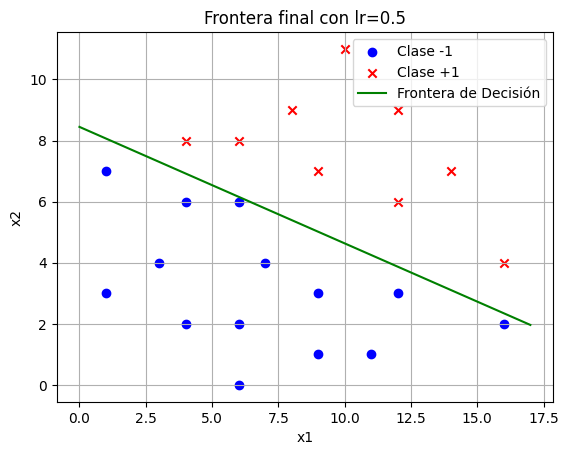

In [12]:
perceptron_plot(X, y, final_w, "Frontera final con lr=0.5")

- Pregunta guía: ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?

Al graficar, se puede observar que la frontera final separa perfectamente los puntos azules de los rojos sin dejar una instancia mal clasificada

La diferencia principal de la frontera inicial es que tenia una posicion e inclinacion muy variante, por lo que no dividia correctamente las clases, pero con el entrenamiento, los pesos y el bias, se logro ajustar el modelo para que pueda trazar la frontera final de forma correcta separando las clases

# Fase 6. Predicción con Nuevas Instancias

Una vez entrenado el perceptrón, se utilizará para clasificar nuevas instancias que no fueron usadas durante el entrenamiento

**6.1 Actividades de predicción**

**Actividad 6.a — Clasificación de nuevas instancias**

Usa perceptron_compute(X_test, final_w) para obtener la salida de cada instancia. Construye una tabla con el siguiente formato:

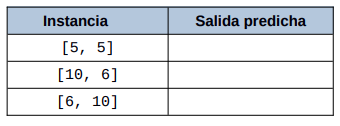


Instancia | Salida Predicha
[5, 5]           -1
[10, 6]           1
[6, 10]           1




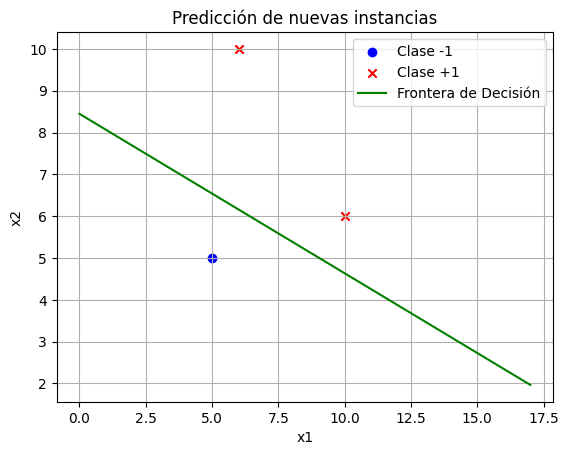

In [13]:
X_test = [[5, 5], [10, 6], [6, 10]]

y_test_pred= []

print("Instancia | Salida Predicha")
for i  in X_test:
  pred= perceptron_compute(i, final_w)
  y_test_pred.append(pred)

  print(f"{str(i)}          ", pred)
print("\n")

perceptron_plot(X_test, y_test_pred, final_w, "Predicción de nuevas instancias")


- Pregunta guía: ¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?


Si son coherentes, cada punto recibe la etiqueta correspondiente al plano en el que cae respecto a la recta aprendida, [5, 5] se ubica en la parte de abajo de la recta (-1), [6, 10] esta en la zona de arriba (+1) y [10, 6] de igual forma estan en la zona de arriba (+1)

**Actividad 6.b — Dataset extendido**

Agrega las nuevas instancias a una copia del dataset original. Agrega también sus salidas predichas al vector de etiquetas.

Luego grafica nuevamente el dataset extendido con la frontera aprendida.

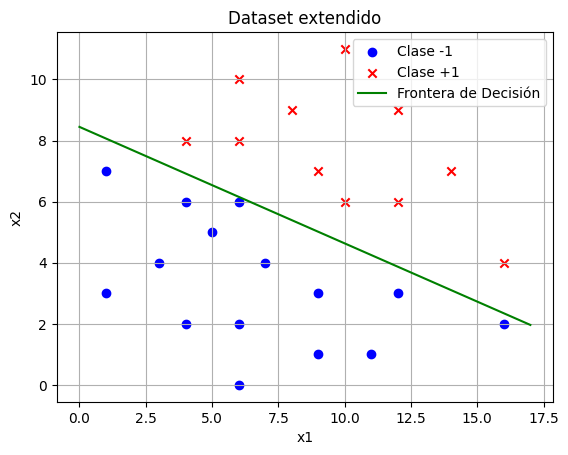

In [14]:
X_extendido= X.copy()
y_extendido= y.copy()

for i in range (len(X_test)):
  X_extendido.append(X_test[i])
  y_extendido.append(y_test_pred[i])

perceptron_plot(X_extendido, y_extendido, final_w, "Dataset extendido")


- Pregunta guía: ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna predicción parece discutible? Justifica tu respuesta

Las nuevas instancias si quedaron ubicadas en la region esperada, [5, 5] quedo rodeado de los puntos de clase -1 y [6, 10] quedo dentro del grupo de clase de +1


La prediccion que puede ser discutible es la instancia [10, 6], pues se encuenta demasiado cerca de la frontera de decision, por lo que en algunas ejecuciones esta instancia pueda que se clasifique como -1 y en otras como +1, pues el perceptron se detiene apenas logra separar los datos de entrenamiento dependiendo de los pesos iniciales, quedando la recta un poco mas arriba o mas abajo


# Fase 7. Evolución de la Frontera de Decisión

**7.1 Actividades de visualización del entrenamiento**

**Actividad 7.a — Seis estados del entrenamiento**

Crea seis gráficas diferentes que muestren la evolución de la frontera de decisión. Selecciona los siguientes momentos:

• Estado inicial

• 20% del entrenamiento

• 40% del entrenamiento

• 60% del entrenamiento

• 80% del entrenamiento

• Estado final


Si el entrenamiento tuvo menos de seis épocas, grafica todos los estados disponibles.

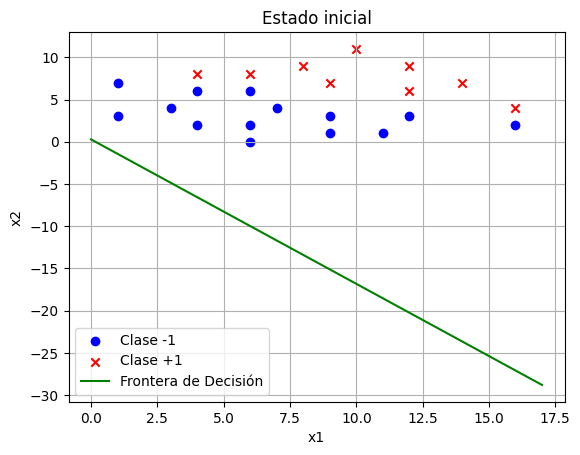

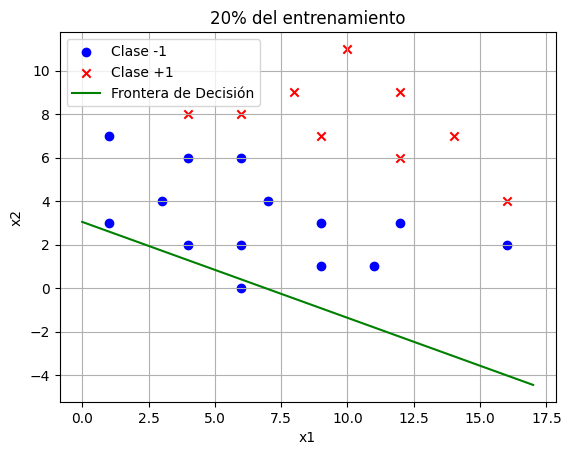

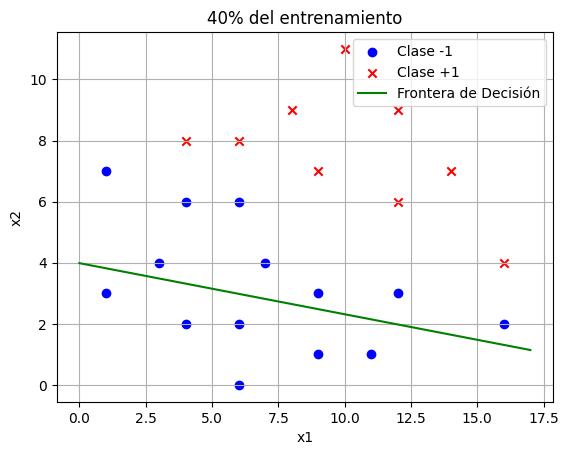

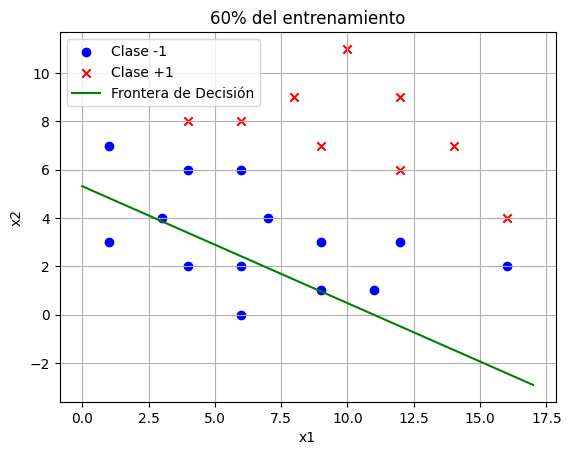

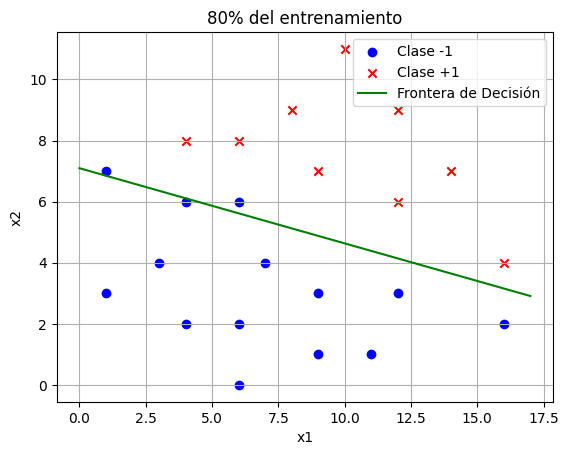

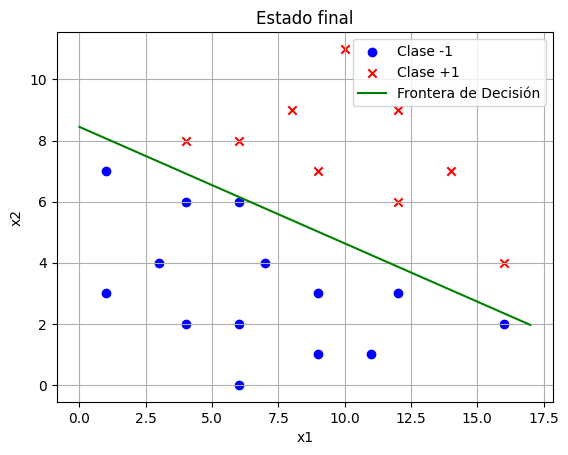

In [15]:
def plot_evolution(X, y, w_inicial, W_values, prefijo=""):
    historial = [w_inicial] + W_values
    total_epocas = len(W_values)

    if total_epocas < 6:
        for i in range(len(historial)):
            perceptron_plot(X, y, historial[i], f"Epoca{i}")
    else:
        porcentajes = [
            ("Estado inicial", 0),
            ("20% del entrenamiento", int(total_epocas * 0.2)),
            ("40% del entrenamiento", int(total_epocas * 0.4)),
            ("60% del entrenamiento", int(total_epocas * 0.6)),
            ("80% del entrenamiento", int(total_epocas * 0.8)),
            ("Estado final", total_epocas)
        ]

        for etiqueta, idx in porcentajes:
            perceptron_plot(X, y, historial[idx], etiqueta)
            print("\n")

plot_evolution(X, y, w, W_values)

- Pregunta guía: ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?


Con cada actualizacion provocada por el error de clasificacion, la recta cambiaba su posicicion e inclinacion progresivamente, hasta que separa las dos clases y ya no quedan puntos mal clasificados


Al inicio del entrenamiento, los cambios fueron muy bruscos, pero a medida que la recta se acercaba a la separacion correcta, los cambios se vuelven menos bruscos y estables hasta converger


**Actividad 7.b — Interpretación geométrica**

- Analiza cómo se desplaza o rota la recta durante el entrenamiento

Al comparar las 6 graficas, se logra ver como la rectar para de una orientacion arbitraria en el estado inicial a rotar y desplazarse hacia la mitad, separando las clases -1 y +1, teniendo una pendiente negativa

- Pregunta guía: ¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?


El peso que mas influye en la inclinacion de la recta depende de la relacion entre los pesos de entrada w1 y w2 en el cociente -w1/w2


El papel que cumple el bias (w0) es controlar el desplazamiento paralelo de la recta a traves de -w0/w2, permitiendo mover la frontera hacia arriba o hacia abajo sin cambiar su inclinacion

# Fase 8. Evolución del Error

**8.1 Actividades sobre el error**

**Actividad 8.a — Gráfica de error**


- Crea una función llamada plot_error(E_values, title) La función debe graficar:

• Eje X: época

• Eje Y: tasa de error

• Título

• Cuadrícula

Luego grafica la evolución del error para el entrenamiento con lr = 0.5.

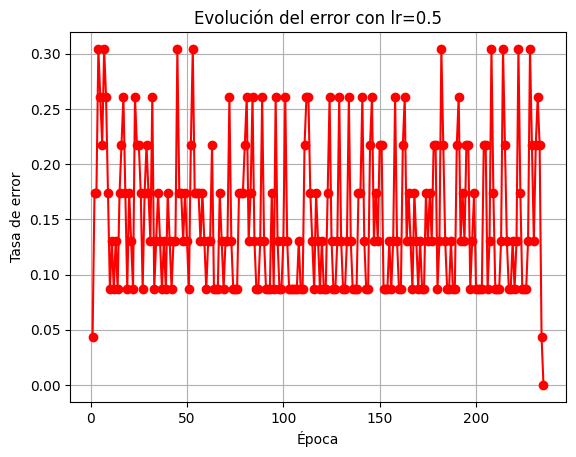

In [16]:
def plot_error(E_values, title):
  epocas = list(range(1, len(E_values)+1))
  plt.plot(epocas, E_values, marker='o', color='red', linestyle='-')
  plt.title(title)
  plt.xlabel('Época')
  plt.ylabel('Tasa de error')
  plt.grid(True)
  plt.show()

plot_error(E_values, "Evolución del error con lr=0.5")

- Pregunta guía: ¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?


El error no necesariamente disminuye de forma continua, al observar la grafica, se puede observar como en algunos momentos el error se mantiene igual o incluso subir en algunas epocas antes de llegar a cero


Puede aumentar o mantenerse igual por que el perceptron actualiza los pesos punto por punto cuando comete un error, al mover la recta para corregir un punto, puede pasar que los otros puntos esten en el lado equivocado cuando antes estaban bien clasificados, haciendo que el error oscile hasta encontrar una posicion que los separe de todos  

**Actividad 8.b — Análisis de convergencia**

- Observa la última época del entrenamiento.

En la ultima epoca de entrenamiento, la curva llega a 0.0, confirmando que el algoritmo convergio y se detuvo antes de llegar al limite de 1000 epocas

- Pregunta guía: ¿Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta.

Que el error final sea igual a cero significa que el perceptron encontro una frontera lineal capaz de clasificar sin ningun error los datos de entrenamiento


No significa que el modelo pueda funcionar para cualquier otro dato futuro, pues el perceptron garantiza que separo los datos que ya conoce, si llegan datos nuevos muy cercanos a la frontera, o con algo de ruido, el modelo podria clasificarlos mal

# Fase 9. Comparación de Tasas de Aprendizaje

**9.1 Actividades de comparación**

**Actividad 9.a — Entrenamiento comparativo**

Inicializa un único vector de pesos iniciales y crea copias para cada valor de lr. Para cada tasa de aprendizaje, registra:

• Pesos finales

• Número de épocas

• Número total de actualizaciones

• Error final


In [17]:
w_base = initialize_weights()
print("Pesos iniciales:", w_base)

tasas = [0.3, 0.5, 0.8]
resultados = {}

for i in tasas:
  final_w_i, epochs_i, updates_i, W_values_i, E_values_i = perceptron_learning(
      X, y, w_base.copy(), lr=i, max_epochs=1000
  )

  resultados[i] = {
      "final_w": final_w_i,
      "epochs": epochs_i,
      "updates": updates_i,
      "error_final": E_values_i[-1],
      "W_values": W_values_i,
      "E_values": E_values_i
  }

  print(f"\nlr = {i}\nÉpocas: {epochs_i}\nActualizaciones: {updates_i}\nError final: {E_values_i[-1]}\nPesos finales: {[round(v, 4) for v in final_w_i]}")

Pesos iniciales: [0.22786403298070645, -0.3886097654276124, 0.04711361860934149]

lr = 0.3
Épocas: 211
Actualizaciones: 742
Error final: 0.0
Pesos finales: [-70.5721, 3.2114, 8.4471]

lr = 0.5
Épocas: 248
Actualizaciones: 836
Error final: 0.0
Pesos finales: [-125.7721, 5.6114, 15.0471]

lr = 0.8
Épocas: 100
Actualizaciones: 312
Error final: 0.0
Pesos finales: [-92.5721, 4.4114, 9.6471]


- Pregunta guía: ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?


Porque los pesos iniciales determinan que tan cerca o lejos empieza la frontera de la solucion correcta, si cada tasa inicia desde un punto distinto, podria darse el caso de que llegue a converger mas rapido por suerte de haber empezado en una mejor ubicacion, y no por el efecto real de la tasa de aprendizaje

**Actividad 9.b — Gráficas comparativas**

- Para cada valor de lr, genera:

• seis gráficas de evolución de la frontera;

• gráfica de evolución del error.



Resultados para lr= 0.3



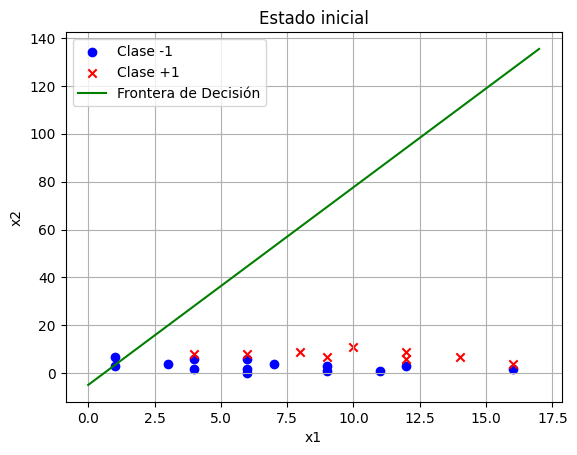

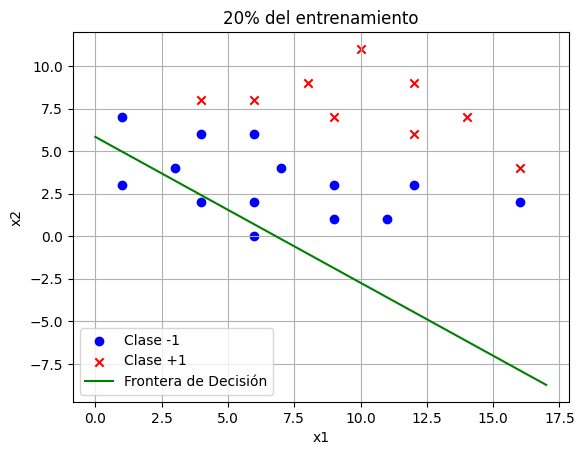

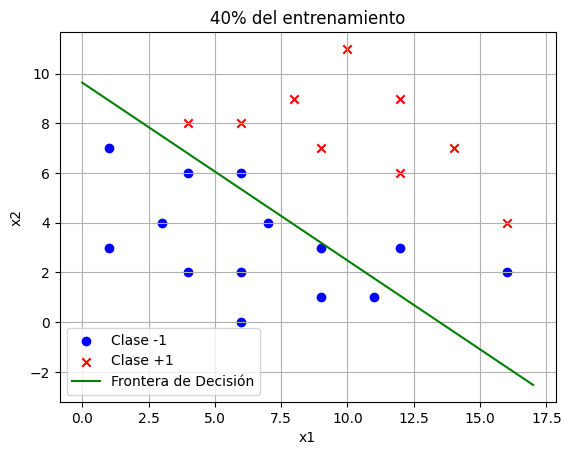

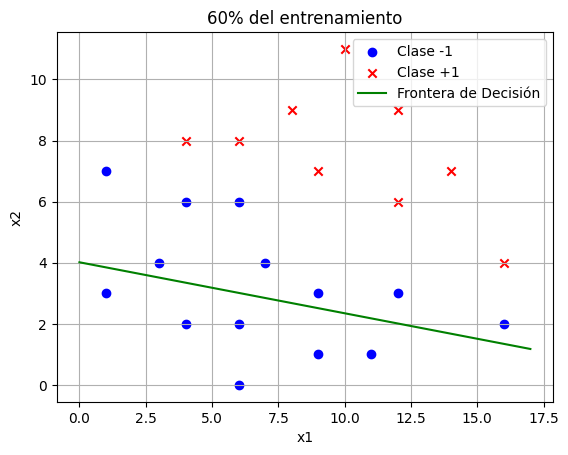

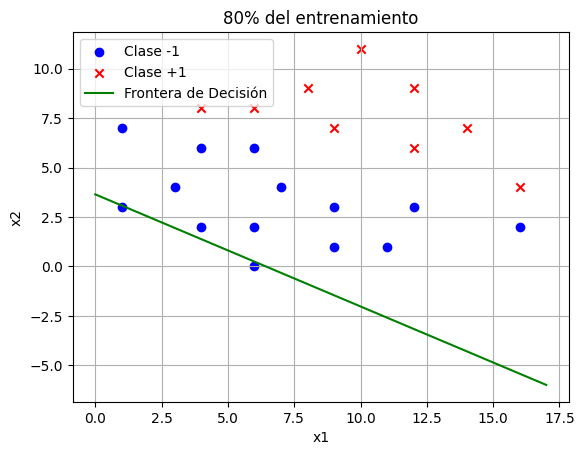

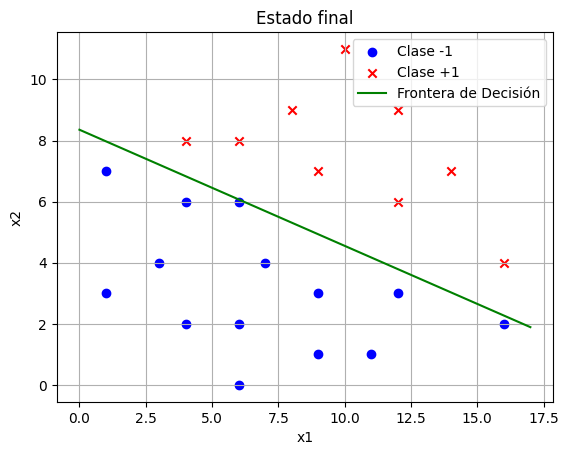

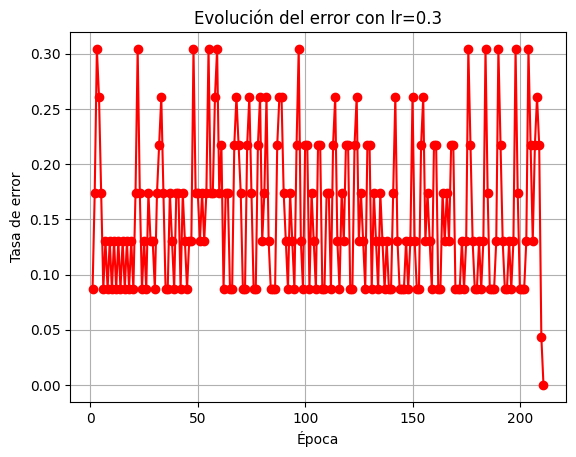


Resultados para lr= 0.5



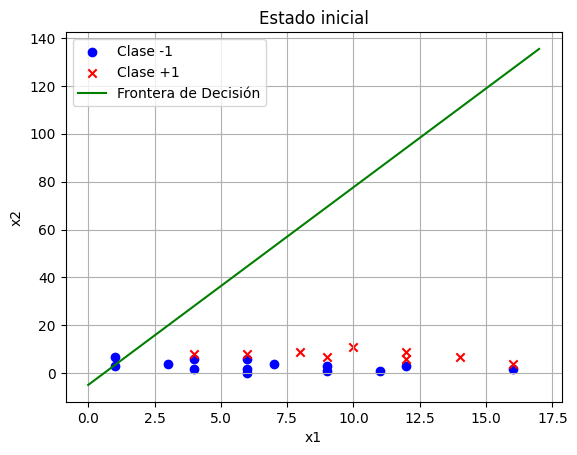

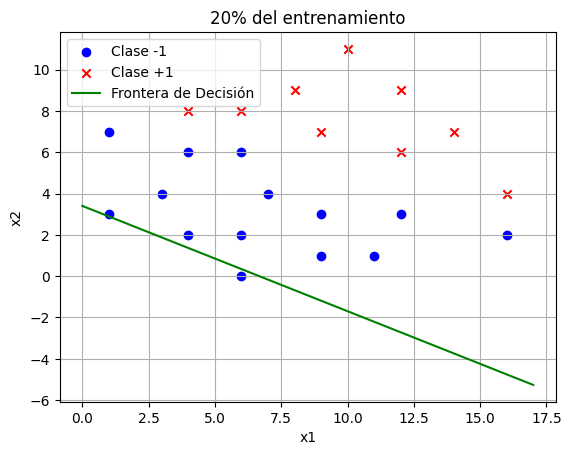

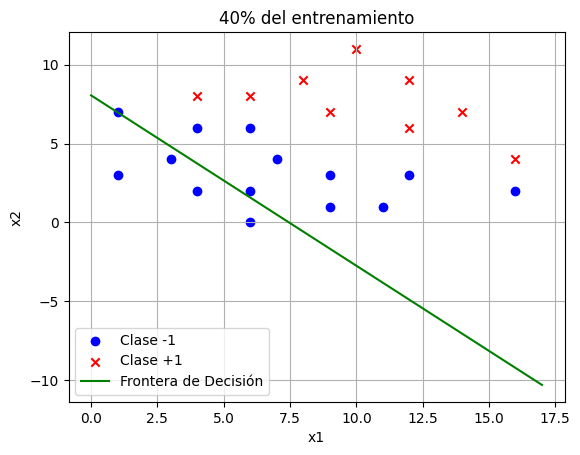

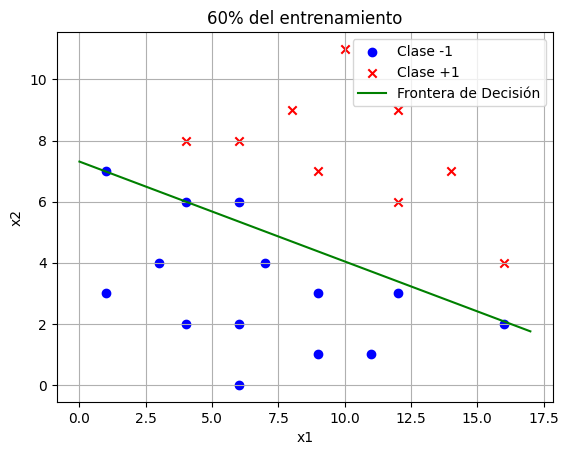

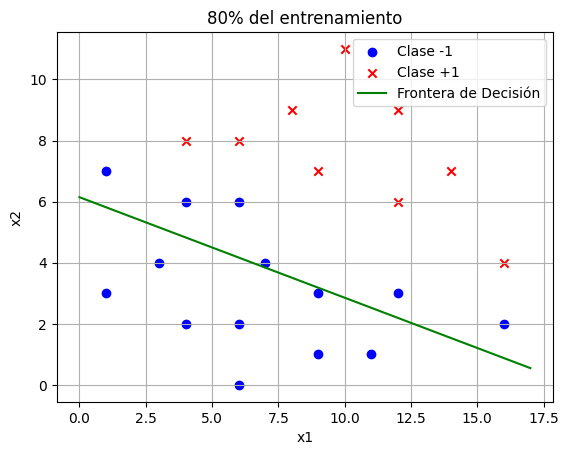

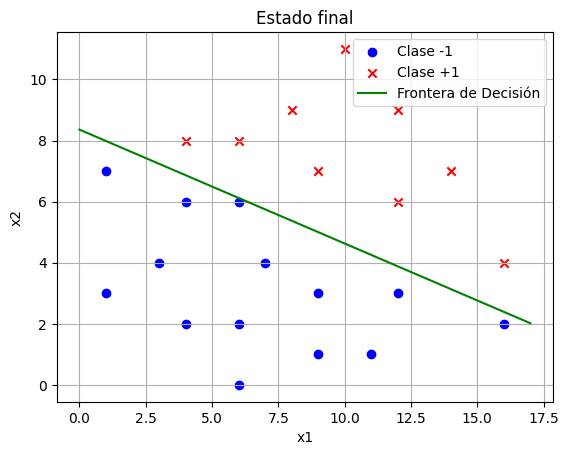

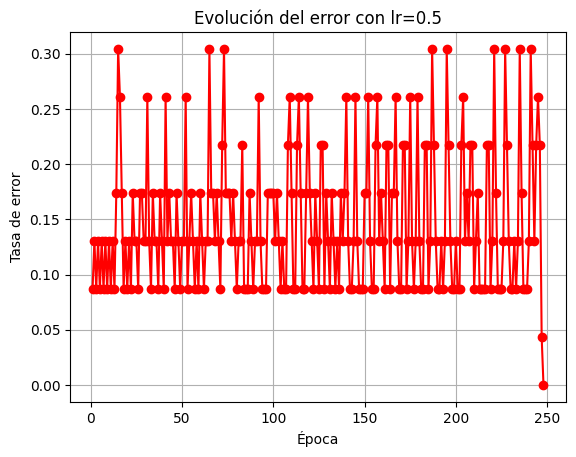


Resultados para lr= 0.8



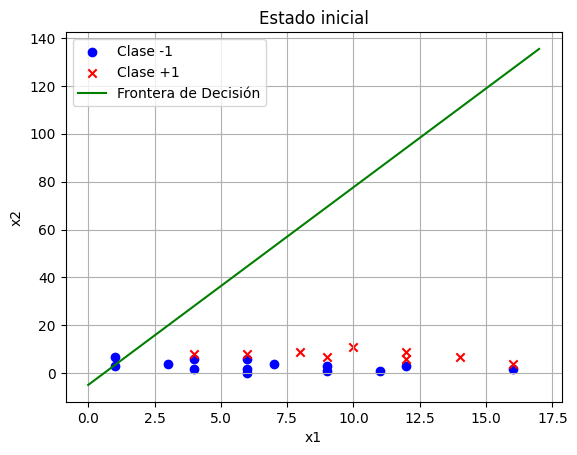

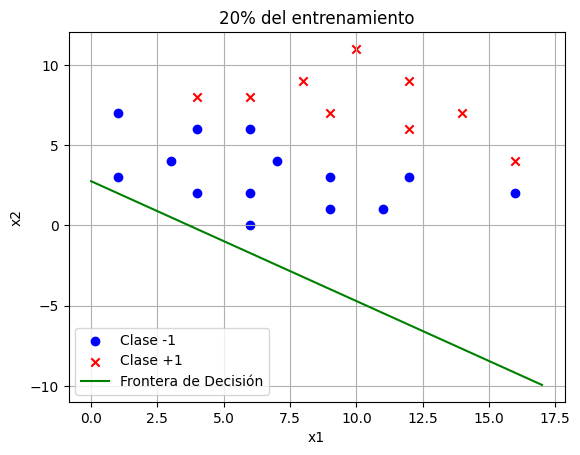

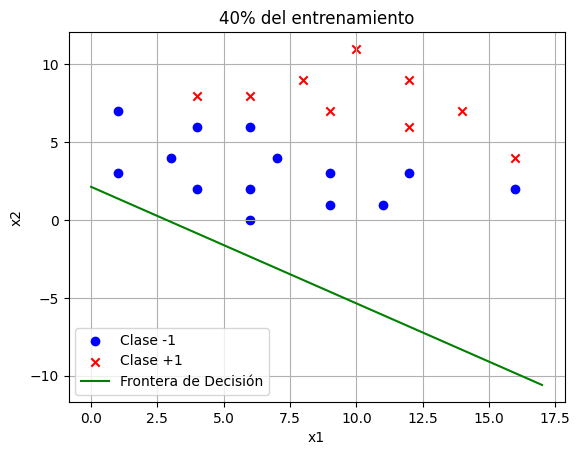

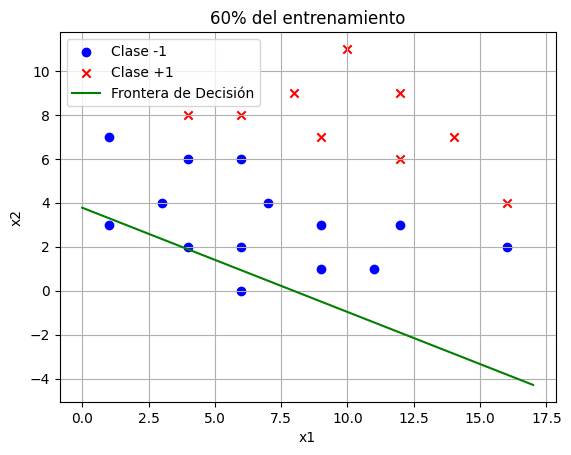

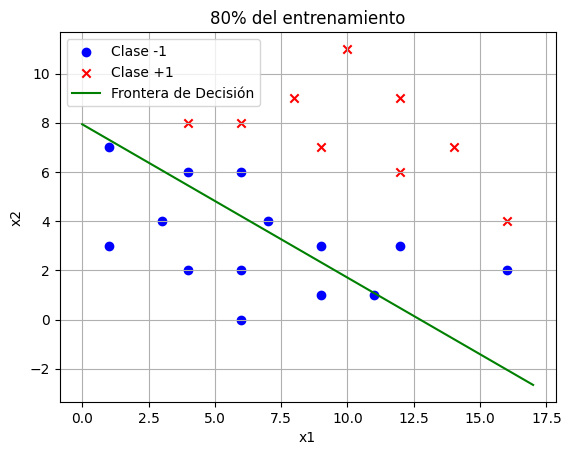

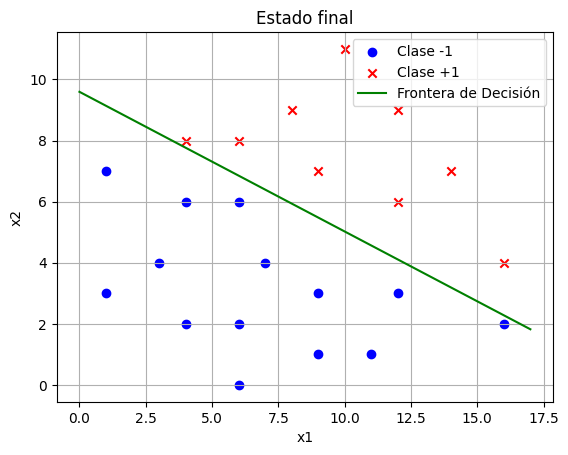

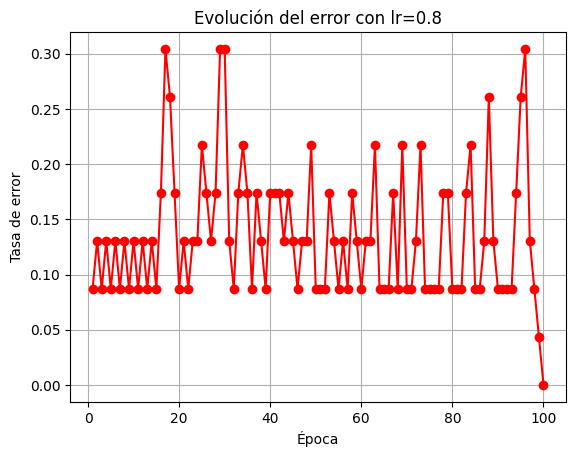

In [18]:
for lr in tasas:
  print(f"\nResultados para lr= {lr}\n")
  res= resultados[lr]
  #Grafica de evolucion de frontera
  plot_evolution(X, y, w_base, res["W_values"])
  print("\n")
  #grafica de evolucion del error
  plot_error(res["E_values"], f"Evolución del error con lr={lr}")




- Pregunta guía: ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?


La tasa de aprendizaje que alcanzo la convergencia con menos epocas fue el lr= 0.8, con 100 epocas


No se puede decir que es la mejor tasa de aprendizaje, pues una tasa de aprendizaje puede dar saltos demasiado grandes y hacer que la frontera oscile de forma brusca, como tambien la tasa mas moderada puede ofrecer un aprendizaje mas estable y controlado, especialmente en datasets mas complejos o con ruido

**Actividad 9.c — Tabla comparativa**

Construye una tabla como la siguiente:

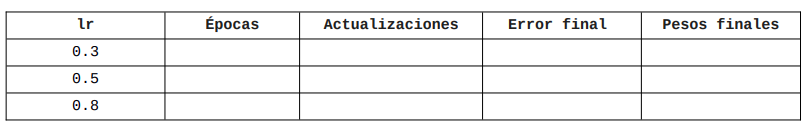

In [20]:
print(f"lr       |  Epocas    |   Actualizaciones  |  Error final  |  Pesos finales")
print("-" * 80)

for lr in tasas:
    r = resultados[lr]
    pesos_redondeados = [round(v, 4) for v in r["final_w"]]

    print(f"{lr:<6}   |   {r['epochs']:<6}   |     {r['updates']:<12}   |   {r['error_final']:<9}   |   {pesos_redondeados}")

lr       |  Epocas    |   Actualizaciones  |  Error final  |  Pesos finales
--------------------------------------------------------------------------------
0.3      |   211      |     742            |   0.0         |   [-70.5721, 3.2114, 8.4471]
0.5      |   248      |     836            |   0.0         |   [-125.7721, 5.6114, 15.0471]
0.8      |   100      |     312            |   0.0         |   [-92.5721, 4.4114, 9.6471]


- Pregunta guía: ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?


Los pesos finales no son iguales porque cada tasa de aprendizaje aplica incrementos de diferente magnitud en cada actualizacion


Se puede producir una clasificacion correcta a pesar de que son diferentes porque entre los dos conjuntos de datos linealmente separables, existen infinitas rectas posibles que logran separar ambas clases sin error

# Conclusiones


1. Implementar el perceptron desde cero permitio comprobar como el ajuste iterativo de los pesos y el bias transforma una recta aleatoria en una frontera funcional y que el modelo se detiene apenas alcanza cero errores sin garantizar el margen optimo

2. La comparacion de tasas de aprendizaje con los mismos pesos iniciales demostro que aunque distintas tasas llevan pesos finales diferentes, todas logran converger en un dataset linealmente separable porque existen multiples rectas que separan las clases